1. Đọc tập dữ liệu cục bộ

In [1]:
import os
import time
import shutil
import tempfile
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)

# Tự động tìm thư mục gốc dự án
cwd = Path.cwd().resolve()
PROJECT_DIR = next(
    (p for p in [cwd, *cwd.parents] if (p / "data" / "processed").is_dir()),
    cwd,
)
data_dir = PROJECT_DIR / "data" / "processed"
models_dir = PROJECT_DIR / "models"
models_dir.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(data_dir / "train.csv")
test_df = pd.read_csv(data_dir / "test.csv")

# Chuẩn bị dữ liệu
X_train = train_df["text"].fillna("").astype(str)
y_train = train_df["label"]
X_test = test_df["text"].fillna("").astype(str)
y_test = test_df["label"]

print("Đã tải dữ liệu thành công!")
print(f"Train: {len(X_train):,} mẫu | Test: {len(X_test):,} mẫu")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Đã tải dữ liệu thành công!
Train: 66,755 mẫu | Test: 16,689 mẫu


2.Huấn luyện mô hình

In [3]:
baseline_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', max_features=20000, ngram_range=(1, 2))),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

start_base = time.time()
baseline_pipeline.fit(X_train, y_train)
base_time = time.time() - start_base

y_pred_base = baseline_pipeline.predict(X_test)
y_prob_base = baseline_pipeline.predict_proba(X_test)[:, 1]

print("=== KẾT QUẢ BASELINE (MẶC ĐỊNH) ===")
print(f"Train Time : {base_time:.2f} giây")
print(f"Accuracy   : {accuracy_score(y_test, y_pred_base):.4f}")
print(f"F1-Score   : {f1_score(y_test, y_pred_base):.4f}")
print(f"ROC-AUC    : {roc_auc_score(y_test, y_prob_base):.4f}")

=== KẾT QUẢ BASELINE (MẶC ĐỊNH) ===
Train Time : 59.08 giây
Accuracy   : 0.9850
F1-Score   : 0.9858
ROC-AUC    : 0.9984


3. Tinh chỉnh siêu tham số (GridSearchCV)

In [4]:
cache_dir = tempfile.mkdtemp(prefix="lr_tfidf_cache_")
try:
    cached_pipeline = Pipeline(
        [
            ("tfidf", TfidfVectorizer(stop_words="english", max_features=20000, ngram_range=(1, 2))),
            ("clf", LogisticRegression(max_iter=1000, random_state=42)),
        ],
        memory=cache_dir,
    )

    param_grid = {
        "clf__C": [0.1, 1.0, 5.0, 10.0],
        "clf__solver": ["lbfgs", "liblinear"],
    }

    grid_search = GridSearchCV(
        estimator=cached_pipeline,
        param_grid=param_grid,
        cv=5,
        scoring="f1",
        n_jobs=-1,
        verbose=1,
    )

    start_tune = time.time()
    grid_search.fit(X_train, y_train)
    tune_time = time.time() - start_tune

    best_params = grid_search.best_params_
    best_model = Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", max_features=20000, ngram_range=(1, 2))),
        ("clf", LogisticRegression(
            C=best_params["clf__C"],
            solver=best_params["clf__solver"],
            max_iter=1000,
            random_state=42,
        )),
    ])
finally:
    shutil.rmtree(cache_dir, ignore_errors=True)

print(f"\nTham số tốt nhất: {grid_search.best_params_}")
print(f"F1-Score trung bình (5-Fold CV): {grid_search.best_score_:.4f}")
print(f"Tổng thời gian chạy GridSearchCV: {tune_time:.2f} giây")

Fitting 5 folds for each of 8 candidates, totalling 40 fits

Tham số tốt nhất: {'clf__C': 10.0, 'clf__solver': 'liblinear'}
F1-Score trung bình (5-Fold CV): 0.9888
Tổng thời gian chạy GridSearchCV: 1823.63 giây


4. Chỉ số thực nghiệm

In [5]:
# Đo thời gian huấn luyện riêng của mô hình tốt nhất
start_fit = time.time()
best_model.fit(X_train, y_train)
best_train_time = time.time() - start_fit

# Đo thời gian dự đoán trên tập Test
start_pred = time.time()
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]
predict_time = time.time() - start_pred

print("=== KẾT QUẢ THỰC NGHIỆM: LOGISTIC REGRESSION (TUNED) ===")
print(f"Best Params      : {grid_search.best_params_}")
print(f"Accuracy         : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision (Spam) : {precision_score(y_test, y_pred):.4f}")
print(f"Recall (Spam)    : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score (Spam)  : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC          : {roc_auc_score(y_test, y_prob):.4f}")
print(f"Train Time       : {best_train_time:.2f} giây")
print(f"Predict Time     : {predict_time:.2f} giây")

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, target_names=['Ham (0)', 'Spam (1)'], digits=4))

=== KẾT QUẢ THỰC NGHIỆM: LOGISTIC REGRESSION (TUNED) ===
Best Params      : {'clf__C': 10.0, 'clf__solver': 'liblinear'}
Accuracy         : 0.9892
Precision (Spam) : 0.9863
Recall (Spam)    : 0.9933
F1-Score (Spam)  : 0.9898
ROC-AUC          : 0.9989
Train Time       : 64.98 giây
Predict Time     : 14.05 giây

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

     Ham (0)     0.9925    0.9847    0.9886      7907
    Spam (1)     0.9863    0.9933    0.9898      8782

    accuracy                         0.9892     16689
   macro avg     0.9894    0.9890    0.9892     16689
weighted avg     0.9892    0.9892    0.9892     16689



5. Biểu đồ Confusion Matrix

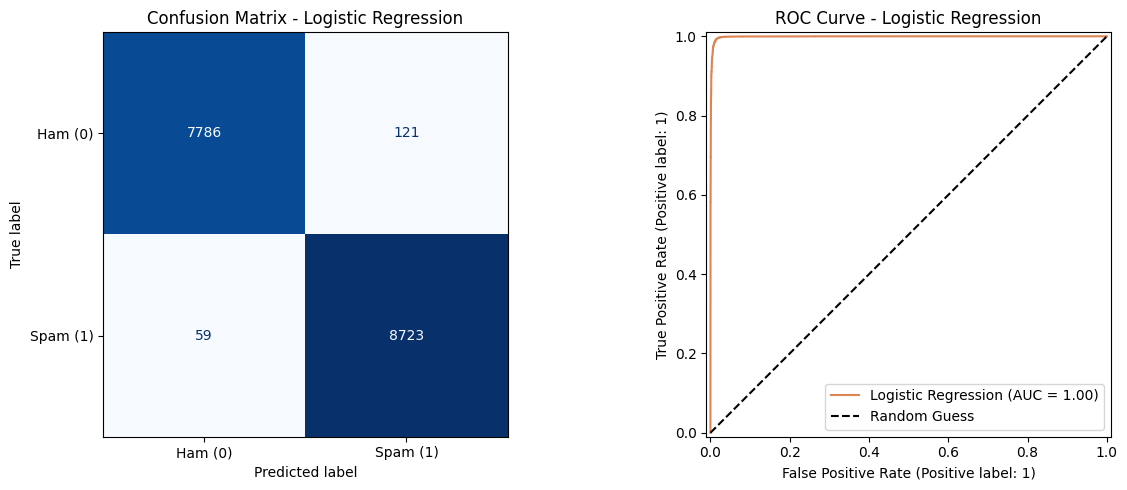

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Ham (0)', 'Spam (1)'])
disp.plot(cmap='Blues', values_format='d', ax=axes[0], colorbar=False)
axes[0].set_title('Confusion Matrix - Logistic Regression')

# 2. ROC Curve
RocCurveDisplay.from_predictions(y_test, y_prob, name='Logistic Regression', ax=axes[1], curve_kwargs={'color': '#DD8452'})
axes[1].plot([0, 1], [0, 1], 'k--', label='Random Guess')
axes[1].set_title('ROC Curve - Logistic Regression')
axes[1].legend()

plt.tight_layout()
plt.show()

6. Kiểm tra các từ đặc trưng & Phân tích lỗi

In [7]:
tfidf = best_model.named_steps['tfidf']
clf = best_model.named_steps['clf']
feature_names = np.array(tfidf.get_feature_names_out())
coefs = clf.coef_[0]

print("Top 10 từ/cụm từ đặc trưng cho SPAM:")
for idx in np.argsort(coefs)[-10:][::-1]:
    print(f"  {feature_names[idx]:<25} : +{coefs[idx]:.4f}")

print("\nTop 10 từ/cụm từ đặc trưng cho HAM:")
for idx in np.argsort(coefs)[:10]:
    print(f"  {feature_names[idx]:<25} : {coefs[idx]:.4f}")

# Xem 5 email dự đoán sai
error_df = pd.DataFrame({
    'text': X_test,
    'true_label': y_test,
    'pred_label': y_pred,
    'spam_prob': y_prob.round(4)
})
errors = error_df[error_df['true_label'] != error_df['pred_label']]
print(f"\nTổng số email đoán sai: {len(errors):,} / {len(y_test):,} ({len(errors)/len(y_test)*100:.2f}%)")
display(errors.head(5))

Top 10 từ/cụm từ đặc trưng cho SPAM:
  2004                      : +8.7877
  2005                      : +8.5289
  http                      : +8.4944
  hk                        : +6.3936
  quality                   : +5.7918
  life                      : +5.7156
  meds                      : +5.6351
  freebsd                   : +5.4301
  price escapenumber        : +5.3968
  men                       : +5.2644

Top 10 từ/cụm từ đặc trưng cho HAM:
  enron                     : -19.1731
  wrote                     : -16.8820
  vince                     : -12.2062
  thanks                    : -11.4299
  perl                      : -11.3544
  samba                     : -11.0624
  louise                    : -10.9519
  debian                    : -10.9334
  attached                  : -9.0573
  713                       : -8.2977

Tổng số email đoán sai: 180 / 16,689 (1.08%)


,text,true_label,pred_label,spam_prob
51,stop making other people rich run your own bus...,1,0,0.4456
52,centroid terminates benzedrine boggled zebra v...,1,0,0.3145
106,i spoke with oscar wyatt this afternoon on cro...,0,1,0.5682
200,' for the record ' questions for the enside ne...,0,1,0.5489
284,you are cracking me up . basically you are the...,0,1,0.6748


7.Test và lưu lại mô hình

In [8]:
import pickle

# 1. Test thử dự đoán 2 email mẫu
def predict_email(text):
    prob = best_model.predict_proba([text])[0][1]
    label = "SPAM" if prob >= 0.5 else "HAM"
    print(f"[{label}] (Xác suất Spam: {prob*100:.2f}%) -> {text[:60]}...")

print("--- DEMO DỰ ĐOÁN ---")
predict_email("Congratulations! You won a free $1000 gift card. Click here to claim your prize now!")
predict_email("Hi team, please find attached the meeting notes from yesterday's project sync.")

# 2. Lưu file mô hình dạng .pkl vào thư mục models/
model_path = models_dir / "logistic_regression_spam_pipeline.pkl"
with open(model_path, "wb") as f:
    pickle.dump(best_model, f)

print(f"\nĐã lưu mô hình thành công tại: {model_path}")

--- DEMO DỰ ĐOÁN ---
[SPAM] (Xác suất Spam: 95.99%) -> Congratulations! You won a free $1000 gift card. Click here ...
[HAM] (Xác suất Spam: 0.06%) -> Hi team, please find attached the meeting notes from yesterd...

Đã lưu mô hình thành công tại: /content/logistic_regression_spam_pipeline.pkl
-> Mở biểu tượng Thư mục (Files) bên thanh trái Colab, tìm file .pkl và bấm dấu 3 chấm -> Tải xuống (Download).


In [9]:
import re
import pickle

try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output
    HAS_WIDGETS = True
except ImportError:
    HAS_WIDGETS = False
    print("ipywidgets chưa được cài đặt - bỏ qua giao diện tương tác.")

if HAS_WIDGETS:
    try:
        model_to_test = best_model
    except NameError:
        with open(models_dir / "logistic_regression_spam_pipeline.pkl", "rb") as f:
            model_to_test = pickle.load(f)

    text_input = widgets.Textarea(
        value="",
        placeholder="Dán hoặc nhập nội dung email tiếng Anh cần kiểm tra vào đây...",
        description="Nội dung:",
        layout=widgets.Layout(width="80%", height="150px"),
    )
    predict_btn = widgets.Button(description="Kiểm tra Email", button_style="primary", icon="search")
    clear_btn = widgets.Button(description="Xóa nội dung", button_style="", icon="trash")
    output_area = widgets.Output()

    def on_predict_clicked(b):
        with output_area:
            clear_output()
            raw_text = text_input.value.strip()
            if not raw_text:
                print("Vui lòng nhập nội dung email trước khi kiểm tra!")
                return
            cleaned = re.sub(r"\s+", " ", raw_text.lower()).strip()
            prob_spam = model_to_test.predict_proba([cleaned])[0][1]
            prob_ham = 1 - prob_spam
            if prob_spam >= 0.5:
                print(f"KẾT QUẢ: SPAM (Thư rác) - Độ tin cậy: {prob_spam * 100:.2f}%")
            else:
                print(f"KẾT QUẢ: HAM (Email bình thường) - Độ tin cậy: {prob_ham * 100:.2f}%")

    def on_clear_clicked(b):
        text_input.value = ""
        with output_area:
            clear_output()

    predict_btn.on_click(on_predict_clicked)
    clear_btn.on_click(on_clear_clicked)
    display(text_input, widgets.HBox([predict_btn, clear_btn]), output_area)

Textarea(value='', description='Nội dung:', layout=Layout(height='150px', width='80%'), placeholder='Dán hoặc …

Output()